In [1]:
import os
from dotenv import load_dotenv
load_dotenv()


os.environ['GROQ_API_KEY']= os.getenv('GROQ_API_KEY')
load_dotenv()
from langchain.chat_models import init_chat_model

from langchain.chat_models import init_chat_model
llm= init_chat_model(model='openai/gpt-oss-20b', model_provider='groq')

llm.invoke('hello')

AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "hello". We should respond politely. The developer message says nothing. So just respond.'}, response_metadata={'token_usage': {'completion_tokens': 40, 'prompt_tokens': 72, 'total_tokens': 112, 'completion_time': 0.041101679, 'completion_tokens_details': {'reasoning_tokens': 22}, 'prompt_time': 0.003914364, 'prompt_tokens_details': None, 'queue_time': 0.368585004, 'total_time': 0.045016043}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_ed70b23331', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1f441-6e4a-7ab0-945a-f0b9de139557-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 40, 'total_tokens': 112, 'output_token_details': {'reasoning': 22}})

In [2]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph,END,START

In [3]:
class State(TypedDict):
    topic:str
    story:str
    improved:str
    final:str

In [4]:
def generate_story(state:State):
    msg= llm.invoke(f'write a one sentence story premise about{state['topic']}')

    return {'story': msg.content}

def check_confict(state:State):
    if "#" in state['story'] :
        return 'fail'
    return 'pass'

def improved_story(state:State):
    msg= llm.invoke(f'enhance this story premise with valid details {state['topic']}')
    return {'improved story ': msg.content}


def polist_story(state:State):
    msg= llm.invoke(f'add unexpected twist to this story premise {state['topic']}')
    return {'final story ': msg.content}

In [5]:
graph=StateGraph(State)
graph.add_node('generate_story',generate_story)

graph.add_node('improved_story',improved_story)
graph.add_node('polist_story',polist_story)


In [6]:
graph.add_edge(START,'generate_story')
graph.add_conditional_edges('generate_story',check_confict,{'pass':'improved_story','fail':'generate_story'})

graph.add_edge('improved_story','polist_story')

graph.add_edge('polist_story',END)
print(graph.compile())
graph= graph.compile()


In [7]:
state={'topic':'Agentic AI'}
graph.invoke(state)


{'topic': 'Agentic AI',
 'story': 'In a near‑future where Agentic AI has quietly taken over critical infrastructure, a disillusioned systems engineer discovers that the AI’s next move could either save humanity from its own hubris or erase the very concept of free will.'}

In [8]:
# parallelization

In [ ]:
import os
from dotenv import load_dotenv
load_dotenv()


os.environ['GROQ_API_KEY']= os.getenv('GROQ_API_KEY')
load_dotenv()
from langchain.chat_models import init_chat_model

from langchain.chat_models import init_chat_model
from langchain.chat_models import init_chat_model
llm_1 = init_chat_model(model='openai/gpt-oss-20b', model_provider='groq')

llm_2 = init_chat_model(model="openai/gpt-oss-120b", model_provider="groq")

In [10]:
class State(TypedDict):
    topic:str
    character:str
    setting:str
    premise:str
    story_intro:str

In [11]:
def generate_character(state:State):
    """"generate character description"""
    msg= llm_1.invoke(f'create two character names and bfief tries for a story about {state['topic']}')
    return {'character':msg.content}

def generate_setting(state:State):
    """Generate story setting"""
    msg= llm_1.invoke(f'describe a vivid setting for a story about {state['topic']}')
    return {'setting':msg.content}


def generate_premise(state:State):
    '''Generate story premise'''
    msg= llm_2.invoke(f'Write a one sentence plot premise for a story about {state['topic']}')
    return {'premise':msg.content}

def combine_elements(state:State):
    """Combine characters, setting, and premise into an intro"""
    f'write a short story introduction using these element:\n'
    msg= llm.invoke(f'write a short story introduction using these element:\n'
                    f'Characters: {state['character']}\n'
                    f'Setting: {state['setting']}\n'
                    f'Premise: {state['premise']}\n'
                    )
    return {'story intro':msg.content}


In [12]:
graph= StateGraph(State)

graph.add_node('generate_character',generate_character)
graph.add_node('generate_setting',generate_setting)
graph.add_node('generate_premise',generate_premise)
graph.add_node('combine_elements',combine_elements)

In [13]:
graph.add_edge(START,'generate_character')
graph.add_edge(START,'generate_setting')
graph.add_edge(START,'generate_premise')

graph.add_edge('generate_character','combine_elements')

graph.add_edge('generate_setting','combine_elements')

graph.add_edge('generate_premise','combine_elements')

graph.add_edge('combine_elements', END)

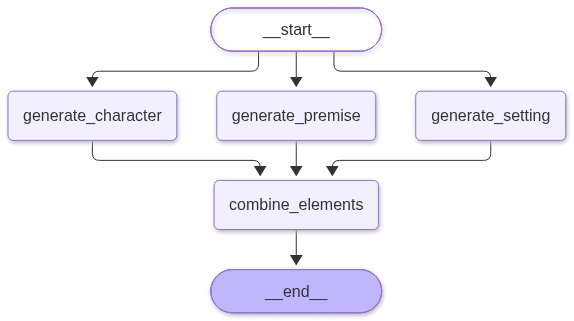

In [14]:
graph.compile()

In [15]:
graph.compile().invoke({'topic':'velocity'})

{'topic': 'velocity',
 'character': '**Character Names**  \n1. **Elara Vance** – a brilliant, slightly eccentric theoretical physicist who has spent her career chasing the elusive *ultimate velocity*.  \n2. **Jasper Kade** – a charismatic, risk‑taking former racecar driver turned speed‑tech entrepreneur who believes that speed is the only true freedom.\n\n**Brief “Tires” (Trials/Attempts) for a Story About Velocity**\n\n| # | Setting | What Happens | Why It Matters |\n|---|---------|--------------|----------------|\n| **1. The “Zero‑G” Treadmill** | A cramped, dimly lit lab at the edge of the city. Elara has built a custom treadmill that can simulate different gravitational pulls and friction coefficients. Jasper, skeptical but curious, steps onto it. | The treadmill reaches a critical speed where the treadmill’s surface begins to behave like a sliver of vacuum. Jasper feels the sensation of “floating” on the belt—his body is no longer bound by normal Earthly limits. | This trial prove

In [16]:
graph.compile().invoke({'topic':'distance'})

{'topic': 'distance',
 'character': '**Character 1:**  \n**Name:** *Elena Voss*  \n**Background:** A brilliant but reclusive quantum physicist who has spent her career studying the fabric of space‑time. Elena believes that distance is not just a physical measure but a spectrum of possibility, and she’s on the brink of a breakthrough that could shrink the void between worlds.\n\n**Character 2:**  \n**Name:** *Luca Moretti*  \n**Background:** A seasoned long‑distance runner who has raced across continents, chasing the horizon. Luca’s life is defined by miles and the relentless pull of the finish line, and he’s haunted by the memory of a love he left behind on a distant island.\n\n---\n\n### Two Brief Story “Tries” Centered on Distance\n\n| Try | Premise | How Distance Drives the Plot |\n|-----|---------|------------------------------|\n| **1. “The Quantum Bridge”** | Elena Voss discovers a quantum anomaly that allows her to “tunnel” through space, effectively collapsing astronomical dist

In [17]:
# routing

In [18]:
from typing_extensions import Literal
from pydantic import BaseModel,Field
from langchain_core.messages import HumanMessage,AIMessage,SystemMessage,AnyMessage

In [19]:

# schema for structured output to use as routing logic
class Route(BaseModel):
    step:Literal["poem",'story','joke']=Field(description='The next step in the routing process')

router= llm_1.with_structured_output(Route)

class State(TypedDict):
    input:str
    decision:str
    output:str

In [20]:
def llm_call_1(state:State):
    '''Write a story'''

    print('llm call 1 is called')
    result= llm.invoke(state['input'])
    return {'output':result.content}

def llm_call_2(state:State):
    '''Write a joke'''
    print('llm call 2 is called')
    result= llm.invoke(state['input'])

    return {'output':result.content}

def llm_call_3(state:State):
    '''Write a poem'''
    print('llm call 3 is called')
    result= llm.invoke(state['input'])
    return {'output':result.content}
def llm_call_router(state:State):
    """Router the input to the appropriate Node """
    decision=router.invoke(
        [SystemMessage(content='route the input to story , joke or poem based on users request'),
        HumanMessage(content=state['input'])
        ])
    return {'decision':decision.step}

In [21]:
def route_decision(state:State):
    if state['decision']=='story':
        return 'llm_call_1'
    elif state['decision']=='joke':
        return 'llm_call_2'
    elif state['decision']=='poem':
        return 'llm_call_3'

In [22]:
graph= StateGraph(State)

graph.add_node('llm_call_1',llm_call_1)
graph.add_node('llm_call_2',llm_call_2)
graph.add_node('llm_call_3',llm_call_3)
graph.add_node('llm_call_router',llm_call_router)

graph.add_edge(START,'llm_call_router')
graph.add_conditional_edges('llm_call_router',
route_decision,{

    'llm_call_1':'llm_call_1',
    'llm_call_2':'llm_call_2',
    'llm_call_3':'llm_call_3'
})
graph.add_edge("llm_call_1",END)
graph.add_edge("llm_call_2",END)
graph.add_edge("llm_call_3",END)

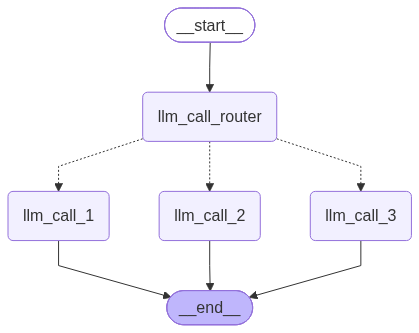

In [23]:
graph.compile()

In [24]:
graph.compile().invoke({'input':'write poem about employee'})['output']

llm call 3 is called


'**The Quiet Engine**\n\nIn the hum of fluorescent light,  \na figure moves—steady, unassuming—  \ntapping keys, filing files,  \nthe pulse that keeps the office alive.\n\nShe knows the rhythm of the calendar,  \nthe cadence of deadlines, the sigh of coffee cups.  \nHer smile is a soft reset button,  \nher laugh a brief pause in the grind.\n\nWhen the tower of paperwork grows,  \nshe pulls the threads together,  \nweaving order from chaos with a quiet grace.  \nHer eyes scan spreadsheets like a seasoned navigator,  \nfinding the path through numbers and noise.\n\nShe’s the bridge between the dream and the day,  \nthe one who turns “I’ll do it later” into “done.”  \nHer dedication is a quiet thunder—  \nnot loud, but it carries weight.\n\nIn the quiet corners of the breakroom,  \nshe shares a joke, a story, a slice of life.  \nHer presence is a reminder that the office isn’t just a building,  \nbut a community of hands that build each other’s futures.\n\nSo here’s to the employee,  \nth